# 01 — Khám phá dữ liệu (EDA) toàn diện cho bài toán dự báo doanh số

Theo nguyên tắc chuẩn mực trong Học máy (Machine Learning):
1. **Khám phá Dữ liệu (EDA) trên toàn bộ dữ liệu**: Khảo sát toàn diện bức tranh dữ liệu nguồn Olist và bảng panel sản phẩm–tuần để nắm rõ quy mô mẫu, độ thưa thớt (sparsity) của biến mục tiêu doanh số (`sales`), phân phối ngoại lai, biến động doanh thu theo thời gian và cơ cấu ngành hàng.
2. **Phân chia chuỗi thời gian (Temporal Split) TRƯỚC khi tiền xử lý**: Dữ liệu sau đó được chia thành Train (80%), Validation (10%) và Test (10%) theo mốc thời gian tuần `order_purchase_timestamp`.
3. **Tiền xử lý độc lập ở Notebook 02**: Toàn bộ tham số tiền xử lý và trích xuất đặc trưng chỉ được `fit` trên tập Train, sau đó mới `transform` sang Validation và Test để loại trừ 100% rủi ro rò rỉ dữ liệu (Data Leakage).

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import CustomDataPipeline, weekly_split_data
from src.models import regressors, persistence
from src.deployment import predictor
from src.evaluation import metrics, error_analysis

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(config.NOTEBOOK_FIGURES_DIR / filename, dpi=config.FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def revenue(log_values):
    return np.maximum(0.0, np.expm1(np.asarray(log_values, dtype=float)))

print("Trình thông dịch Trình thông dịch Python:", sys.executable)
print("Thư mục dự án:", PROJECT_ROOT)

Trình thông dịch Trình thông dịch Python: e:\Hoc_May_Tren_truong\lab_2 sales_predictor\.venv\Scripts\python.exe
Thư mục dự án: e:\Hoc_May_Tren_truong\lab_2 sales_predictor


## 1. Dữ liệu nguồn và cấu trúc bảng sản phẩm–tuần (Weekly Panel)

`load_raw_sales_data` nạp dữ liệu Olist và chuẩn hóa doanh thu từng dòng về `price`. Bảng panel tổng hợp giao dịch theo từng sản phẩm và tuần lịch bắt đầu từ thứ Hai. Các tuần không phát sinh giao dịch sau lần bán đầu tiên được giữ nguyên với `sales = 0`.

In [2]:
raw = load_raw_sales_data()
panel = build_weekly_sales_dataset(raw)
display(pd.DataFrame({"Chỉ số dữ liệu": ["Số dòng giao dịch nguồn (raw items)", "Tổng số dòng panel sản phẩm–tuần", "Số lượng sản phẩm duy nhất", "Số tuần lịch quan sát"],
                      "Giá trị": [f"{len(raw):,}", f"{len(panel):,}", f"{panel.product_id.nunique():,}", f"{panel[config.TIMESTAMP_COLUMN].nunique():,}"]}))
source_columns = ["product_id", "price", config.TIMESTAMP_COLUMN, "product_category_name"]
display(raw[[c for c in source_columns if c in raw]].isna().mean().rename("Tỷ lệ khuyết (Missing fraction)").to_frame())
display(panel.head())

[2026-11-05 10:29:35] [INFO] [sales_predictor]: [DATA AUDIT] Tham số reviews=None; tự động nạp dữ liệu đánh giá từ tệp chuẩn: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\raw\olist_order_reviews_dataset.csv


,Chỉ số dữ liệu,Giá trị
0,Số dòng giao dịch nguồn (raw items),"110,197"
1,Tổng số dòng panel sản phẩm–tuần,"1,198,182"
2,Số lượng sản phẩm duy nhất,"31,835"
3,Số tuần lịch quan sát,98


,Tỷ lệ khuyết (Missing fraction)
product_id,0.000000
price,0.000000
order_purchase_timestamp,0.000000
product_category_name,0.013948


,product_id,order_purchase_timestamp,category,price,sales,last_week_sales,sales_lag_2_weeks,sales_lag_4_weeks,sales_mean_4_weeks,sales_std_4_weeks,last_week_units,weeks_since_first_sale,customer_past_spend,customer_past_orders,customer_state_count,past_review_count,past_review_rating
0,027cdd14a677a5834bc67a9789db5021,2016-10-10,perfumaria,89.90,0.0,89.90,0.0,0.0,89.90,0.0,1.0,1,0.0,0.0,1,0.0,0.0
1,0534940d69bf94dc61c0e722b4168235,2016-10-10,moveis_decoracao,22.90,0.0,22.90,0.0,0.0,22.90,0.0,1.0,1,0.0,0.0,1,0.0,0.0
2,05fca08b4d54ab5d1d371db7d5534136,2016-10-10,informatica_acessorios,161.55,0.0,161.55,0.0,0.0,161.55,0.0,1.0,1,0.0,0.0,1,0.0,0.0
3,062619359d5f9a664606cb2a6ccb477a,2016-10-10,beleza_saude,136.90,0.0,136.90,0.0,0.0,136.90,0.0,1.0,1,0.0,0.0,1,0.0,0.0
4,0980718a7bdcf89f5848b202b6394965,2016-10-10,beleza_saude,79.99,0.0,79.99,0.0,0.0,79.99,0.0,1.0,1,0.0,0.0,1,0.0,0.0


## 2. Phân bố biến mục tiêu Doanh số trên toàn bộ dữ liệu (Full Panel)

Khảo sát biến mục tiêu `sales` trên toàn bộ 1,198,182 dòng sản phẩm–tuần. Doanh thu bằng 0 là quan sát thực tế hợp lệ (tuần sản phẩm không bán được). Ta phân tích riêng phân bố tổng thể và đuôi phân phối của các tuần có doanh thu dương.

,Phân bố Doanh số tuần (BRL) - Toàn bộ Panel
count,1.198182e+06
mean,6.618886e+00
std,6.671801e+01
min,0.000000e+00
50%,0.000000e+00
90%,0.000000e+00
95%,0.000000e+00
99%,1.790000e+02
max,1.149600e+04


Tỷ lệ tuần không phát sinh doanh số (Zero Sales) trên toàn bộ panel: 96.21%


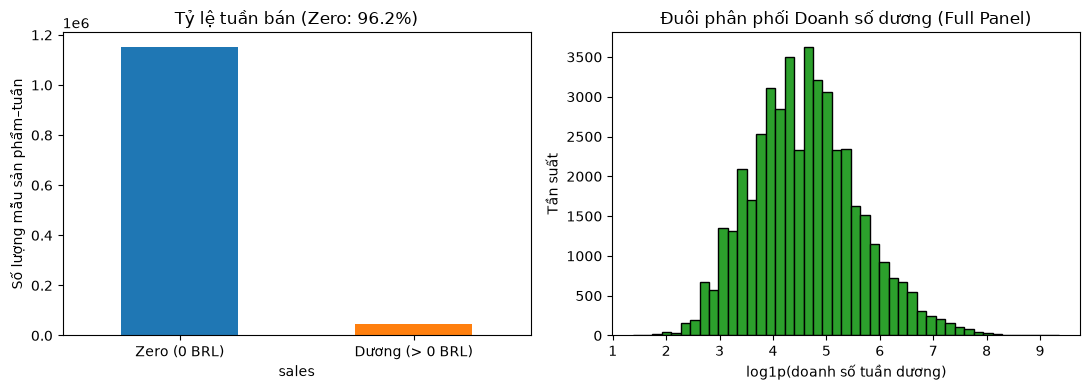

In [3]:
display(panel.sales.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).rename("Phân bố Doanh số tuần (BRL) - Toàn bộ Panel").to_frame())
zero_pct_panel = panel.sales.eq(0).mean() * 100
print(f"Tỷ lệ tuần không phát sinh doanh số (Zero Sales) trên toàn bộ panel: {zero_pct_panel:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
panel.sales.eq(0).value_counts().reindex([True, False], fill_value=0).plot.bar(ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_xticks([0, 1], ["Zero (0 BRL)", "Dương (> 0 BRL)"], rotation=0)
axes[0].set_title(f"Tỷ lệ tuần bán (Zero: {zero_pct_panel:.1f}%)")
axes[0].set_ylabel("Số lượng mẫu sản phẩm–tuần")

axes[1].hist(np.log1p(panel.loc[panel.sales > 0, "sales"]), bins=45, color='#2ca02c', edgecolor='black')
axes[1].set(xlabel="log1p(doanh số tuần dương)", ylabel="Tần suất", title="Đuôi phân phối Doanh số dương (Full Panel)")
show_figure(fig, "weekly_01_target_full_panel.png")

## 3. Xu hướng doanh thu và biến động chuỗi thời gian (Full Panel)

Theo dõi tổng doanh thu và số lượng sản phẩm được quan sát theo từng tuần lịch trên toàn bộ dải thời gian từ 2016 đến 2018.

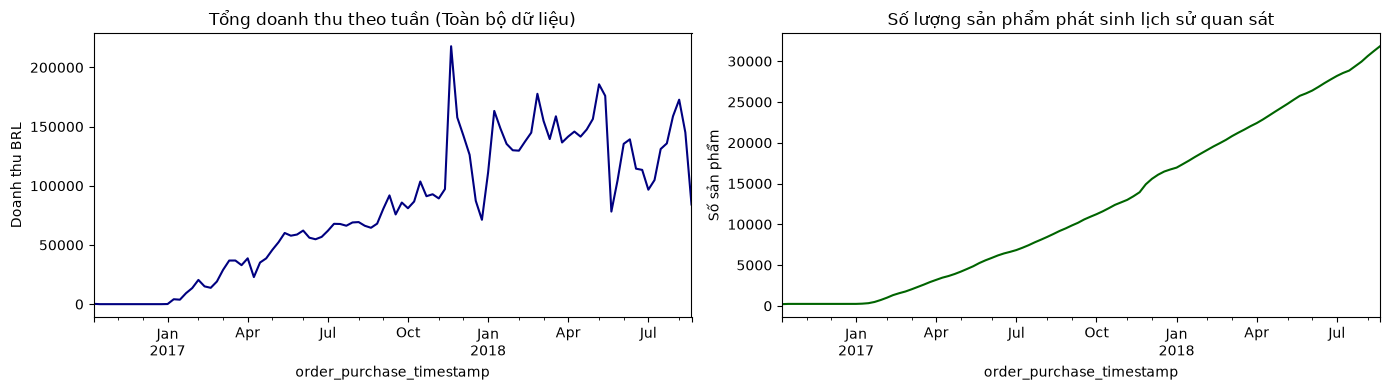

,total_brl,mean_brl,products,positive_rate
order_purchase_timestamp,,,,
2018-06-18,114436.75,4.189214,27317,2.672329
2018-06-25,113414.45,4.085388,27761,2.665610
2018-07-02,96678.64,3.429658,28189,2.256199
2018-07-09,104814.74,3.670627,28555,1.803537
2018-07-16,131046.71,4.542347,28850,2.835355
2018-07-23,135798.90,4.619482,29397,2.789400
2018-07-30,158738.65,5.300476,29948,3.112061
2018-08-06,172711.64,5.639564,30625,3.102041
2018-08-13,145051.53,4.643135,31240,2.922535


In [4]:
weekly_totals = panel.groupby(config.TIMESTAMP_COLUMN).agg(
    total_brl=("sales", "sum"),
    mean_brl=("sales", "mean"),
    products=("product_id", "nunique"),
    positive_rate=("sales", lambda s: (s > 0).mean() * 100)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
weekly_totals.total_brl.plot(ax=axes[0], color='navy')
axes[0].set(title="Tổng doanh thu theo tuần (Toàn bộ dữ liệu)", ylabel="Doanh thu BRL")
weekly_totals.products.plot(ax=axes[1], color='darkgreen')
axes[1].set(title="Số lượng sản phẩm phát sinh lịch sử quan sát", ylabel="Số sản phẩm")
show_figure(fig, "weekly_01_revenue_trend_full.png")
display(weekly_totals.tail(10))

NameError: name 'train_df' is not defined

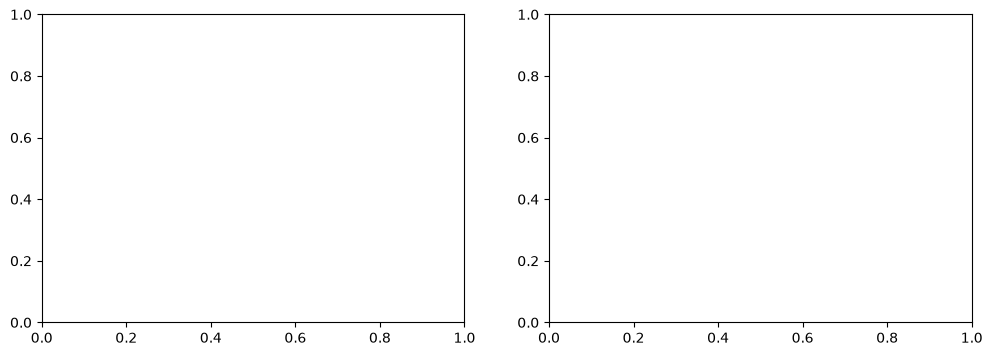

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df.groupby(config.TIMESTAMP_COLUMN).sales.sum().plot(ax=axes[0])
axes[0].set(title="Train weekly target revenue", ylabel="BRL", xlabel="Target week")
train_df.groupby("category").sales.sum().nlargest(10).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Top categories — Train", xlabel="BRL", ylabel="Category")
show_figure(fig, "weekly_01_trends_categories.png")

In [ ]:
zero_pct = train_df.sales.eq(0).mean() * 100
display(Markdown(f"""### Nhận xét từ lần chạy này
- Nguồn có **{len(raw):,}** dòng item; panel có **{len(panel):,}** mẫu sản phẩm–tuần.
- **{zero_pct:.2f}%** target Train bằng 0; đây là bài toán doanh thu thưa. Cần so sánh với baseline trước khi kết luận mô hình tốt.
- Trung vị Train là **{train_df.sales.median():.2f} BRL**; phân vị 99% là **{train_df.sales.quantile(.99):.2f} BRL**. MAE thấp vẫn có thể che sai số ở các tuần doanh thu lớn.
- Chia tập theo **số tuần**, vì vậy tỷ lệ số dòng sản phẩm không bắt buộc bằng 80/10/10.
"""))

### Nhận xét từ lần chạy này
- Nguồn có **110,197** dòng item; panel có **1,198,182** mẫu sản phẩm–tuần.
- **95.40%** target Train bằng 0; đây là bài toán doanh thu thưa. Cần so sánh với baseline trước khi kết luận mô hình tốt.
- Trung vị Train là **0.00 BRL**; phân vị 99% là **199.99 BRL**. MAE thấp vẫn có thể che sai số ở các tuần doanh thu lớn.
- Chia tập theo **số tuần**, vì vậy tỷ lệ số dòng sản phẩm không bắt buộc bằng 80/10/10.


## 4. Kiểm toán trước và sau aggregation

Đếm riêng dòng item, khóa item trùng, product thiếu, ngày/giá không hợp lệ và trạng thái đơn. Không gọi số dòng item là số đơn hàng. Bảng coverage nguồn không dùng để chọn mô hình; phân tích target bên dưới giới hạn trong Train.

Panel loại tuần biên và tuần bán đầu tiên. Vì vậy chênh lệch doanh thu raw/panel là thay đổi tập quan sát, không mặc định là mất dữ liệu hoặc lỗi tổng hợp.

,Count
Item rows,110197
Distinct orders,96478
Duplicate order/item keys,0
Missing product ID,0
Invalid/missing purchase date,0
Missing/non-positive price,0
Non-delivered rows,0


,item_rows,source_revenue,active_products
week,,,
2016-09-12,3,134.97,1
2016-10-03,276,37165.54,208
2016-10-10,37,3159.57,34
2016-12-19,1,10.90,1


,item_rows,source_revenue,active_products
week,,,
2018-08-06,2211,270236.80,1565
2018-08-13,2032,243458.02,1508
2018-08-20,1187,125412.50,945
2018-08-27,132,10565.86,117


,Scope,Revenue BRL
0,Source items,13221498.11
1,Forecast target panel,7930629.66


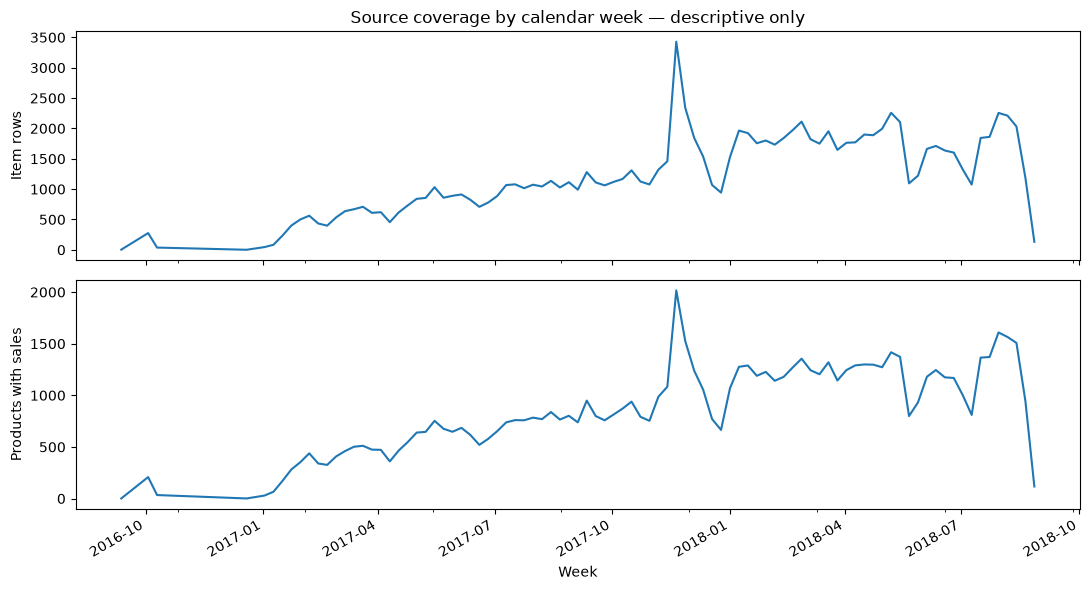

Nguồn có **96,478 đơn** và **110,197 item rows**; **0** khóa item trùng. Tuần đầu/cuối trong bảng coverage cần thận trọng vì phạm vi thu thập không bảo đảm đủ tuần.

In [ ]:
source_audit = pd.Series({
    "Item rows": len(raw), "Distinct orders": raw.order_id.nunique(),
    "Duplicate order/item keys": int(raw.duplicated(["order_id", "order_item_id"]).sum()),
    "Missing product ID": int(raw.product_id.isna().sum()),
    "Invalid/missing purchase date": int(pd.to_datetime(raw[config.TIMESTAMP_COLUMN], errors="coerce").isna().sum()),
    "Missing/non-positive price": int((pd.to_numeric(raw.price, errors="coerce").fillna(0) <= 0).sum()),
    "Non-delivered rows": int(raw.order_status.ne("delivered").sum()) if "order_status" in raw else 0,
}, name="Count")
display(source_audit.to_frame())
source_week = pd.to_datetime(raw[config.TIMESTAMP_COLUMN]).dt.to_period("W-SUN").dt.start_time
coverage = raw.assign(week=source_week).groupby("week").agg(item_rows=("price", "size"), source_revenue=("price", "sum"), active_products=("product_id", "nunique"))
display(coverage.head(4)); display(coverage.tail(4))
display(pd.DataFrame({"Scope": ["Source items", "Forecast target panel"], "Revenue BRL": [raw.price.sum(), panel.sales.sum()]}))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
coverage.item_rows.plot(ax=axes[0]); axes[0].set(ylabel="Item rows", title="Source coverage by calendar week — descriptive only")
coverage.active_products.plot(ax=axes[1]); axes[1].set(ylabel="Products with sales", xlabel="Week")
show_figure(fig, "weekly_01_source_coverage.png")
display(Markdown(f"Nguồn có **{raw.order_id.nunique():,} đơn** và **{len(raw):,} item rows**; **{source_audit['Duplicate order/item keys']:,}** khóa item trùng. Tuần đầu/cuối trong bảng coverage cần thận trọng vì phạm vi thu thập không bảo đảm đủ tuần."))

## 5. Độ thưa và vòng đời quan sát của sản phẩm

Vòng đời ở đây chỉ là khoảng sản phẩm xuất hiện trong **Train**, không phải vòng đời kinh doanh thật. Builder tiếp tục tạo tuần 0 đến hết cửa sổ quan sát; sản phẩm đã ngừng bán có thể tạo nhiều tuần 0. Không dùng lần bán cuối trong tương lai làm feature hoặc quyết định cắt panel.

,observed_weeks,positive_weeks,zero_fraction,revenue_brl
count,22411.000000,22411.000000,22411.000000,22411.000000
mean,29.229664,1.344117,0.951110,234.864951
std,18.318771,3.258957,0.109893,1127.775573
min,1.000000,0.000000,0.000000,0.000000
25%,14.000000,0.000000,0.948718,0.000000
50%,27.000000,0.000000,1.000000,0.000000
75%,44.000000,1.000000,1.000000,119.800000
max,78.000000,60.000000,1.000000,37833.700000


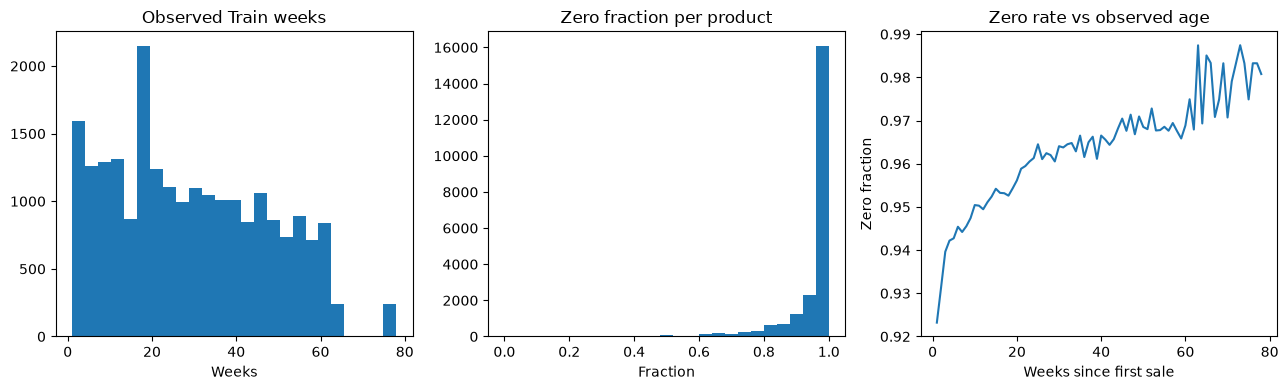

Trong Train, **60.21%** sản phẩm không có target dương trong cửa sổ được quan sát; đây có thể là sản phẩm chỉ bán ở tuần lịch sử đầu tiên. Trung vị có **0** tuần target dương/sản phẩm. Độ thưa giải thích vì sao baseline rất quan trọng.

In [ ]:
product_profile = train_df.groupby("product_id").agg(observed_weeks=("sales", "size"), positive_weeks=("sales", lambda s: int((s > 0).sum())), revenue_brl=("sales", "sum"), first_target=(config.TIMESTAMP_COLUMN, "min"), last_target=(config.TIMESTAMP_COLUMN, "max"))
product_profile["zero_fraction"] = 1 - product_profile.positive_weeks / product_profile.observed_weeks
display(product_profile[["observed_weeks", "positive_weeks", "zero_fraction", "revenue_brl"]].describe())
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(product_profile.observed_weeks, bins=25); axes[0].set(title="Observed Train weeks", xlabel="Weeks")
axes[1].hist(product_profile.zero_fraction, bins=25); axes[1].set(title="Zero fraction per product", xlabel="Fraction")
train_df.groupby("weeks_since_first_sale").sales.apply(lambda s: s.eq(0).mean()).plot(ax=axes[2])
axes[2].set(title="Zero rate vs observed age", xlabel="Weeks since first sale", ylabel="Zero fraction")
show_figure(fig, "weekly_01_sparsity_lifecycle.png")
display(Markdown(f"Trong Train, **{(product_profile.positive_weeks == 0).mean()*100:.2f}%** sản phẩm không có target dương trong cửa sổ được quan sát; đây có thể là sản phẩm chỉ bán ở tuần lịch sử đầu tiên. Trung vị có **{product_profile.positive_weeks.median():.0f}** tuần target dương/sản phẩm. Độ thưa giải thích vì sao baseline rất quan trọng."))

## 6. Giá, outlier và mức tập trung doanh thu

`price` của panel là giá đã biết trước target, không phải giá trung bình của target. Quy tắc IQR dùng để **mô tả**, không tự động loại/cap tuần doanh thu cao. Với nhiều target 0, IQR của toàn bộ doanh thu có thể bằng 0; tính thêm IQR trên các target dương để tránh gọi mọi lần bán là outlier.

,Variable,Q1,Q3,IQR,Upper fence,Above fence (%)
0,Prior price,39.9,149.99,110.09,315.125,8.349998
1,Revenue all weeks,0.0,0.00,0.00,0.000,4.598468
2,Revenue positive weeks,49.0,185.05,136.05,389.125,9.345019


C:\Users\ASUS\AppData\Local\Temp\ipykernel_23968\390916704.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(np.log1p(train_df.loc[train_df.sales > 0, "sales"]), vert=True)


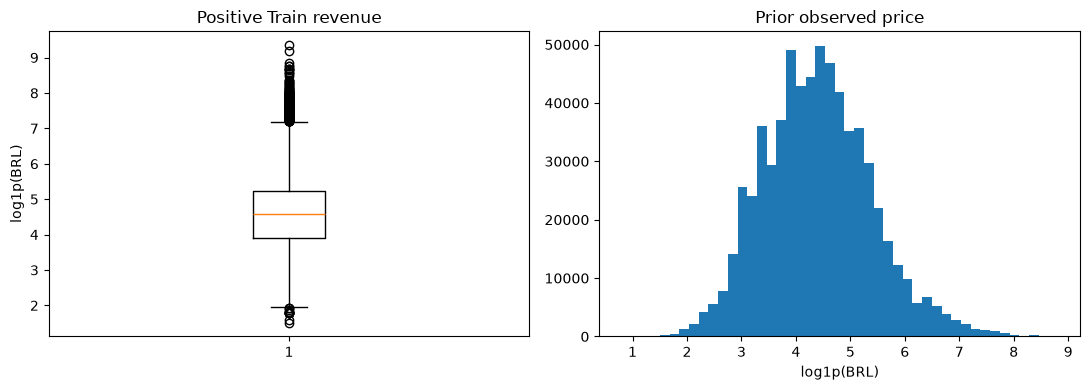

**1%** mẫu Train có target lớn nhất đóng góp **63.09%** doanh thu Train. RMSE nhạy với các mẫu này; cần đọc kèm MAE và sai số theo nhóm doanh thu. Không xóa chúng chỉ để làm đẹp điểm số.

In [ ]:
outliers = []
for label, values in [("Prior price", train_df.price), ("Revenue all weeks", train_df.sales), ("Revenue positive weeks", train_df.loc[train_df.sales > 0, "sales"])]:
    q1, q3 = values.quantile([.25, .75]); spread = q3 - q1
    outliers.append({"Variable": label, "Q1": q1, "Q3": q3, "IQR": spread, "Upper fence": q3 + 1.5*spread, "Above fence (%)": (values > q3 + 1.5*spread).mean()*100})
display(pd.DataFrame(outliers))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].boxplot(np.log1p(train_df.loc[train_df.sales > 0, "sales"]), vert=True)
axes[0].set(title="Positive Train revenue", ylabel="log1p(BRL)")
axes[1].hist(np.log1p(train_df.price), bins=45); axes[1].set(title="Prior observed price", xlabel="log1p(BRL)")
show_figure(fig, "weekly_01_prices_outliers.png")
ordered = train_df.sales.sort_values(ascending=False).to_numpy()
top_count = max(1, int(np.ceil(.01 * len(ordered))))
top_share = ordered[:top_count].sum() / ordered.sum()
display(Markdown(f"**1%** mẫu Train có target lớn nhất đóng góp **{top_share*100:.2f}%** doanh thu Train. RMSE nhạy với các mẫu này; cần đọc kèm MAE và sai số theo nhóm doanh thu. Không xóa chúng chỉ để làm đẹp điểm số."))

## 7. Mùa vụ và cơ cấu danh mục

Đối chiếu tổng doanh thu với trung bình trên product-week và số sản phẩm quan sát. Tổng tăng có thể do catalog mở rộng thay vì nhu cầu mỗi sản phẩm tăng. So sánh tháng gộp nhiều năm chỉ mang tính mô tả; chưa có seasonal holdout hoặc causal experiment để kết luận về lễ hội.

,total_brl,mean_brl,samples
month,,,
1,719089.10,7.890805,91130
2,658013.97,7.777851,84601
3,725055.71,7.586725,95569
4,277001.50,7.564214,36620
5,274916.26,11.261983,24411
6,229959.92,9.159560,25106
7,332777.35,8.918058,37315
8,268026.85,7.459903,35929
9,334041.04,8.039302,41551


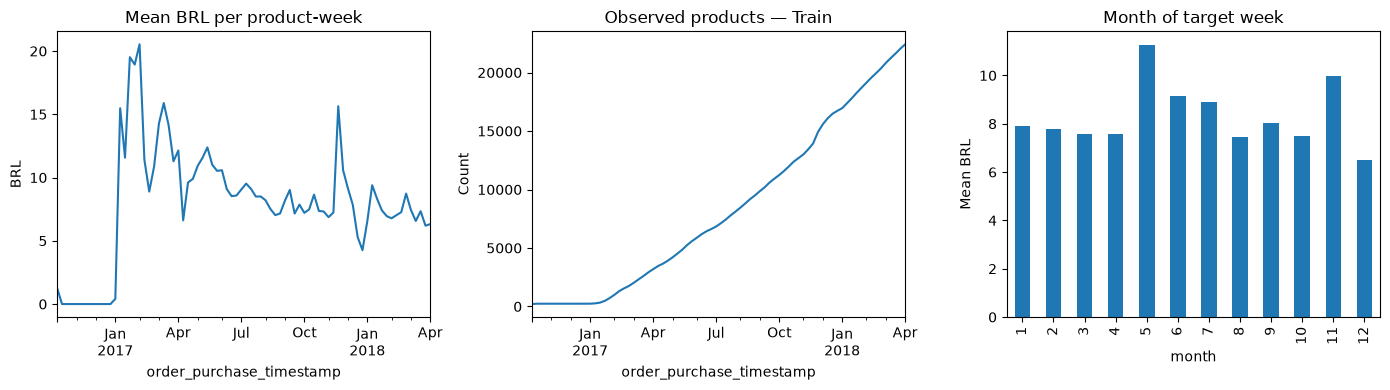

,samples,total_brl,mean_brl,positive_fraction
category,,,,
beleza_saude,41536,485449.39,11.687437,0.053448
cama_mesa_banho,60604,456090.77,7.525754,0.053808
informatica_acessorios,34598,434631.25,12.562323,0.060350
relogios_presentes,26782,413616.01,15.443806,0.056344
esporte_lazer,60571,381303.13,6.295143,0.043139
cool_stuff,22617,344083.28,15.213480,0.062121
moveis_decoracao,67458,254116.78,3.767037,0.029930
ferramentas_jardim,17214,223008.93,12.955091,0.047868
brinquedos,30499,217507.41,7.131624,0.043313


Tháng có mean revenue cao nhất trong Train là **5**, nhưng số mẫu/thành phần sản phẩm khác nhau giữa tháng. Danh mục dẫn đầu doanh thu là **beleza_saude**; chưa thể coi đây là danh mục dễ dự báo nhất nếu chưa xem sai số theo nhóm.

In [ ]:
weekly_train = train_df.groupby(config.TIMESTAMP_COLUMN).agg(total_brl=("sales", "sum"), mean_brl=("sales", "mean"), products=("product_id", "nunique"), positive_fraction=("sales", lambda s: (s > 0).mean()))
monthly = train_df.assign(month=train_df[config.TIMESTAMP_COLUMN].dt.month).groupby("month").agg(total_brl=("sales", "sum"), mean_brl=("sales", "mean"), samples=("sales", "size"))
display(monthly)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
weekly_train.mean_brl.plot(ax=axes[0]); axes[0].set(title="Mean BRL per product-week", ylabel="BRL")
weekly_train.products.plot(ax=axes[1]); axes[1].set(title="Observed products — Train", ylabel="Count")
monthly.mean_brl.plot.bar(ax=axes[2]); axes[2].set(title="Month of target week", ylabel="Mean BRL")
show_figure(fig, "weekly_01_calendar_normalized.png")
category_profile = train_df.groupby("category").agg(samples=("sales", "size"), total_brl=("sales", "sum"), mean_brl=("sales", "mean"), positive_fraction=("sales", lambda s: (s > 0).mean())).sort_values("total_brl", ascending=False)
display(category_profile.head(12))
display(Markdown(f"Tháng có mean revenue cao nhất trong Train là **{monthly.mean_brl.idxmax()}**, nhưng số mẫu/thành phần sản phẩm khác nhau giữa tháng. Danh mục dẫn đầu doanh thu là **{category_profile.index[0]}**; chưa thể coi đây là danh mục dễ dự báo nhất nếu chưa xem sai số theo nhóm."))

## 8. Quan hệ lag–target và tương quan trên Train

Chỉ dùng các biến đầu vào đã có trước target. Pearson trên dữ liệu gốc nhạy với đuôi lớn; Spearman kiểm tra quan hệ đơn điệu. Lag có tương quan không chứng minh nhân quả và không bảo đảm persistence là baseline tốt trên Validation. Các rolling/lag tương quan với nhau có thể làm importance bị phân tán.

,Pearson with target,Spearman with target
price,0.062970,-0.009122
last_week_sales,0.372606,0.223642
sales_lag_2_weeks,0.265561,0.194879
sales_lag_4_weeks,0.217008,0.159224
sales_mean_4_weeks,0.353454,0.223496
sales_std_4_weeks,0.253617,0.214839
last_week_units,0.286049,0.225818
weeks_since_first_sale,-0.022429,-0.051348


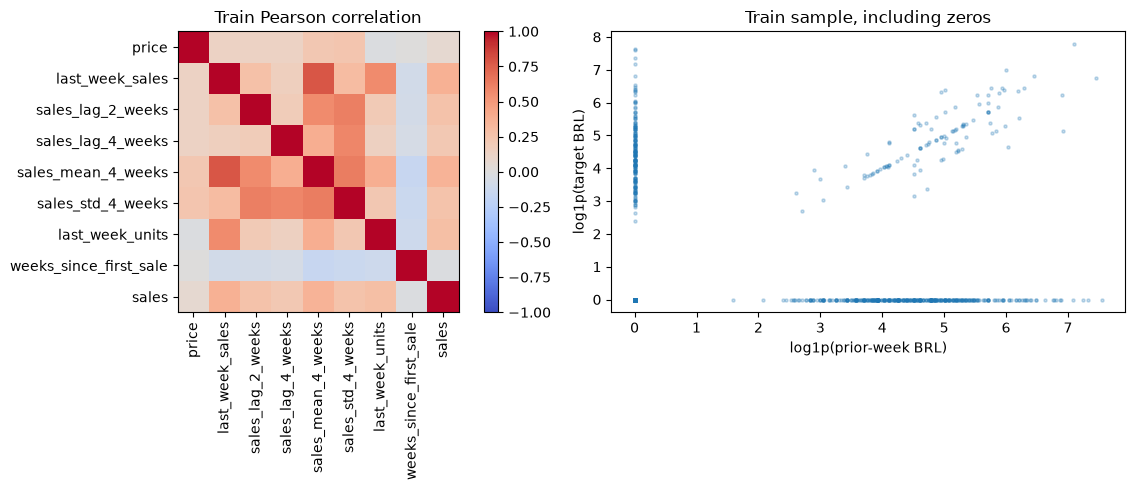

Pearson giữa doanh thu tuần trước và target là **0.3726**; Spearman là **0.2236**. Cần kiểm tra baseline ngoài Train thay vì suy ra khả năng dự báo chỉ từ scatter plot.

In [ ]:
eda_cols = ["price", "last_week_sales", "sales_lag_2_weeks", "sales_lag_4_weeks", "sales_mean_4_weeks", "sales_std_4_weeks", "last_week_units", "weeks_since_first_sale", "sales"]
pearson = train_df[eda_cols].corr()
spearman = train_df[eda_cols].corr(method="spearman")
display(pd.DataFrame({"Pearson with target": pearson.sales.drop("sales"), "Spearman with target": spearman.sales.drop("sales")}))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
image = axes[0].imshow(pearson, vmin=-1, vmax=1, cmap="coolwarm")
axes[0].set_xticks(range(len(eda_cols)), eda_cols, rotation=90); axes[0].set_yticks(range(len(eda_cols)), eda_cols); axes[0].set_title("Train Pearson correlation")
fig.colorbar(image, ax=axes[0], fraction=.04)
sample = train_df.sample(min(6000, len(train_df)), random_state=config.RANDOM_STATE)
axes[1].scatter(np.log1p(sample.last_week_sales), np.log1p(sample.sales), s=5, alpha=.25)
axes[1].set(xlabel="log1p(prior-week BRL)", ylabel="log1p(target BRL)", title="Train sample, including zeros")
show_figure(fig, "weekly_01_lag_correlation.png")
display(Markdown(f"Pearson giữa doanh thu tuần trước và target là **{pearson.loc['last_week_sales', 'sales']:.4f}**; Spearman là **{spearman.loc['last_week_sales', 'sales']:.4f}**. Cần kiểm tra baseline ngoài Train thay vì suy ra khả năng dự báo chỉ từ scatter plot."))

## Kết luận và giới hạn dữ liệu

Giữ target 0 và các đỉnh doanh thu hợp lệ; fit tiền xử lý trên Train ở notebook 02. Dữ liệu không có trạng thái catalog/tồn kho, nên không phân biệt được ngừng bán, hết hàng và nhu cầu thực bằng 0. Cohort delivered theo ngày mua là dữ liệu hồi cứu; chưa mô phỏng độ trễ biết kết quả giao hàng. Các giới hạn này không được giải quyết chỉ bằng temporal split.

In [ ]:

# Đặc trưng lịch sử bổ sung, chỉ khảo sát trên Train.
historical = ['past_review_count', 'past_review_rating', 'customer_past_spend', 'customer_past_orders', 'customer_state_count']
display(train_df[historical].describe())
display(train_df[historical + ['sales']].corr(method='spearman'))
display(Markdown('Review chỉ được tính sau thời điểm trả lời. Chi tiêu khách hàng là lịch sử quan sát, không phải CLV tương lai. Thiếu tuổi, giới tính và dữ liệu chiến dịch thực.'))


,past_review_count,past_review_rating,customer_past_spend,customer_past_orders,customer_state_count
count,655066.000000,655066.000000,655066.000000,655066.000000,655066.000000
mean,2.311909,3.827343,2.963550,0.023889,1.058785
std,5.915969,1.571388,35.267927,0.186657,0.307162
min,0.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,3.285714,0.000000,0.000000,1.000000
50%,1.000000,4.500000,0.000000,0.000000,1.000000
75%,2.000000,5.000000,0.000000,0.000000,1.000000
max,377.000000,5.000000,2600.000000,8.000000,12.000000


,past_review_count,past_review_rating,customer_past_spend,customer_past_orders,customer_state_count,sales
past_review_count,1.000000,0.123582,0.030706,0.030591,0.260525,0.143580
past_review_rating,0.123582,1.000000,0.014256,0.014334,-0.043098,-0.041535
customer_past_spend,0.030706,0.014256,1.000000,0.999934,0.018146,0.005459
customer_past_orders,0.030591,0.014334,0.999934,1.000000,0.017873,0.005374
customer_state_count,0.260525,-0.043098,0.018146,0.017873,1.000000,0.150318
sales,0.143580,-0.041535,0.005459,0.005374,0.150318,1.000000


Review chỉ được tính sau thời điểm trả lời. Chi tiêu khách hàng là lịch sử quan sát, không phải CLV tương lai. Thiếu tuổi, giới tính và dữ liệu chiến dịch thực.

## 9. Phân chia Chuỗi thời gian (Temporal Split 8:1:1) TRƯỚC khi Tiền xử lý

Sau khi đã hoàn thành khám phá toàn diện dữ liệu, ta áp dụng nguyên tắc cốt lõi: **Chia dữ liệu trước khi tiền xử lý**.
- Phân chia 80% Train, 10% Validation, 10% Test theo trục thời gian `order_purchase_timestamp`.
- Ranh giới thời gian rạch ròi, đảm bảo không có bất kỳ thông tin nào từ tương lai bị rò rỉ vào tập Train.
- Tập Train sau khi chia sẽ được chuyển giao sang **Notebook 02** để `fit` Pipeline tiền xử lý và trích xuất đặc trưng.

In [ ]:
train_df, val_df, test_df = weekly_split_data(panel)
split_summary = pd.DataFrame([
    {"Tập dữ liệu": name, "Số mẫu sản phẩm–tuần": f"{len(frame):,}", "Số tuần lịch": frame[config.TIMESTAMP_COLUMN].nunique(),
     "Bắt đầu": str(frame[config.TIMESTAMP_COLUMN].min())[:10], "Kết thúc": str(frame[config.TIMESTAMP_COLUMN].max())[:10],
     "Tỷ lệ Zero sales (%)": f"{frame.sales.eq(0).mean() * 100:.2f}%"}
    for name, frame in [("Train (80%)", train_df), ("Validation (10%)", val_df), ("Test (10%)", test_df)]
])
display(split_summary)
assert train_df[config.TIMESTAMP_COLUMN].max() < val_df[config.TIMESTAMP_COLUMN].min()
assert val_df[config.TIMESTAMP_COLUMN].max() < test_df[config.TIMESTAMP_COLUMN].min()
print("✓ XÁC NHẬN: Phân chia chuỗi thời gian hoàn tất, ranh giới Train < Val < Test hoàn toàn không chồng lấn.")